# Endterm Project: Real-Time Monitoring, Time-Series Analysis and Stream Intelligence
**Astana Smart-City Air Quality (PM2.5) Stream**, extending Assignment 3 (Astana weather/PM2.5 anomaly detection)

Assignment 3 used 14 points from a single sensor. This project builds a complete streaming system on top of it:

```
 data generator ──► producer ──► partitioned queues ──► worker pool (N threads) ──► results queue ──► live dashboard
 (4 districts,       (key =       (crc32(sensor_id)     per event: features,        (sink)            + metrics
  1-min readings)    sensor_id)    % N partitions)      anomaly detection, ML)
```

| Requirement | Where |
|---|---|
| Continuously updated visualization (≥2 charts) | §4 live dashboard (4 panels, refreshed while the stream runs) |
| Time-series analysis | §6 resampling, rolling windows, trend + daily seasonality decomposition |
| Anomaly detection + evaluation | §3 (online rolling MAD and rolling z-score), §7 precision/recall/F1 |
| Real-time ML component | §3 online SGD forecaster (PM2.5 at t+5 min, test-then-train) |
| Features only from information available at prediction time | §3 feature definitions, §8 |
| ML evaluation (MAE/RMSE) | §8 vs. a persistence baseline |
| Distributed stream processing | §3/§4 producer, partitioned streams, multiple consumer workers; §5 scaling run |
| ≥2 operational metrics | §5 throughput, end-to-end latency (p50/p95/p99), backlog, event count per worker |

## 1. Setup and configuration
All parameters are in one `CONFIG` dict, which is also saved to `config.json`. With a fixed seed every run produces the same dataset.

In [1]:
import os, time, json, zlib, queue, threading, sys
from collections import deque, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, mean_absolute_error, mean_squared_error)

CONFIG = {
    'seed': 42,
    'sensors': ['Yesil', 'Almaty', 'Saryarka', 'Baikonur'],   # Astana districts
    'start': '2026-11-01 00:00',
    'days': 3,                    # 3 days x 1440 min x 4 sensors = 17,280 events
    'n_partitions': 2,            # = number of consumer workers
    'replay_rate_eps': 1500,      # producer speed in events/second (0 = as fast as possible)
    'baseline_window': 30,        # previous minutes used as the anomaly baseline
    'min_history': 15,            # minimum history before scoring / predicting
    'mad_k': 4.0,                 # robust z threshold (rolling median / MAD)
    'z_k': 3.0,                   # classic z threshold (rolling mean / std)
    'horizon_min': 5,             # forecast PM2.5 five minutes ahead
    'ml_batch': 32,               # mini-batch size for partial_fit
    'warmup_min': 360,            # first 6 h excluded from ML evaluation (model warm-up)
    'dashboard_refresh_s': 1.5,
}
os.makedirs('data', exist_ok=True)
with open('config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__)

Python 3.14.5 | pandas 3.0.6 | numpy 2.5.3


## 2. Data generator
Synthetic 1-minute PM2.5 readings for 4 Astana districts over 3 days. Each series is built from known parts, so every result can be checked against the ground truth:

* **level**: a different base level per district (25–40 µg/m³)
* **daily seasonality**: a morning traffic peak (~08:00) and a larger evening peak (~19:00, heating and traffic)
* **trend**: +3 µg/m³ per day (slowly worsening air)
* **weather effect**: stronger wind disperses pollution (−1.5 µg/m³ per m/s above 4 m/s)
* **noise**: AR(1) correlated noise plus white sensor noise
* **injected, labelled anomalies**: 6 *pollution spikes* (+50–100 for 5–15 min) and 2 *sensor dropouts* (≈0 for 3–7 min) per sensor

The labels (`is_anomaly`, `anomaly_type`) are used **only for evaluation**. The detectors never see them.

In [2]:
def generate_dataset(cfg):
    rng = np.random.default_rng(cfg['seed'])
    idx = pd.date_range(cfg['start'], periods=cfg['days'] * 1440, freq='1min')
    n = len(idx)
    hour = (idx.hour + idx.minute / 60).to_numpy()
    day_frac = np.arange(n) / 1440
    frames = []
    for i, s in enumerate(cfg['sensors']):
        base = 25 + 5 * i
        season = 10 * np.exp(-((hour - 8) / 2) ** 2) + 14 * np.exp(-((hour - 19) / 2.5) ** 2)
        trend = 3 * day_frac
        ar = np.zeros(n)
        eps = rng.normal(0, 0.6, n)
        for t in range(1, n):
            ar[t] = 0.95 * ar[t - 1] + eps[t]
        temp = -8 + 4 * np.sin(2 * np.pi * (hour - 9) / 24) + rng.normal(0, 0.3, n)
        wind = np.clip(4 + 1.5 * np.sin(2 * np.pi * day_frac / 1.7 + i) + rng.normal(0, 0.5, n), 0, None)
        pm = base + season + trend - 1.5 * (wind - 4) + ar + rng.normal(0, 1.0, n)

        label = np.zeros(n, dtype=int)
        kind = np.array(['normal'] * n, dtype=object)
        for _ in range(6):                                   # pollution spikes
            st, L = rng.integers(120, n - 30), rng.integers(5, 16)
            pm[st:st + L] += rng.uniform(50, 100)
            label[st:st + L], kind[st:st + L] = 1, 'spike'
        for _ in range(2):                                   # sensor dropouts
            st, L = rng.integers(120, n - 30), rng.integers(3, 8)
            pm[st:st + L] = rng.uniform(0, 2, L)
            label[st:st + L], kind[st:st + L] = 1, 'dropout'

        frames.append(pd.DataFrame({
            'timestamp': idx, 'sensor_id': s,
            'pm25': np.clip(pm, 0, None).round(2), 'temp_c': temp.round(2), 'wind_mps': wind.round(2),
            'is_anomaly': label, 'anomaly_type': kind}))
    return (pd.concat(frames).sort_values(['timestamp', 'sensor_id'])
              .reset_index(drop=True))

data = generate_dataset(CONFIG)
data.to_csv('data/astana_pm25_stream.csv', index=False)
print(data.shape)
print(data.groupby('anomaly_type').size())
data.head()

(17280, 7)
anomaly_type
dropout       40
normal     17017
spike        223
dtype: int64


,timestamp,sensor_id,pm25,temp_c,wind_mps,is_anomaly,anomaly_type
0,2026-11-01 00:00:00,Almaty,29.07,-10.56,4.24,0,normal
1,2026-11-01 00:00:00,Baikonur,37.13,-11.53,4.25,0,normal
2,2026-11-01 00:00:00,Saryarka,33.41,-11.18,5.52,0,normal
3,2026-11-01 00:00:00,Yesil,23.67,-11.04,4.44,0,normal
4,2026-11-01 00:01:00,Almaty,27.81,-10.44,5.14,0,normal


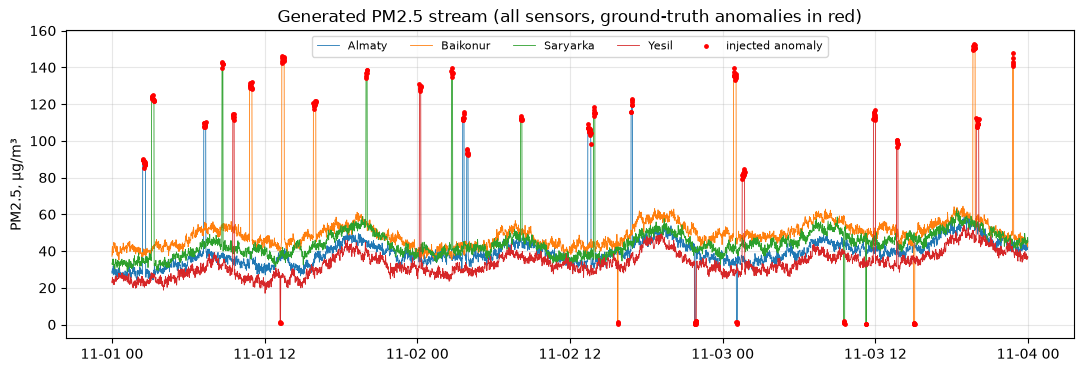

In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
for s, g in data.groupby('sensor_id'):
    ax.plot(g['timestamp'], g['pm25'], lw=0.6, label=s)
an = data[data.is_anomaly == 1]
ax.scatter(an['timestamp'], an['pm25'], s=6, c='red', label='injected anomaly', zorder=3)
ax.set_title('Generated PM2.5 stream (all sensors, ground-truth anomalies in red)')
ax.set_ylabel('PM2.5, µg/m³'); ax.legend(ncol=5, fontsize=8); ax.grid(alpha=0.3)
plt.show()

## 3. Stream processing components

### 3.1 Partitioning (producer side)
Each event is routed by `crc32(sensor_id) % N`. Python's built-in `hash()` of a string changes between runs, so a stable hash is used. All events of a sensor go to the same partition, and each partition is read by exactly one worker, so **per-sensor event order is preserved**. The online state (rolling windows, pending forecasts) depends on that order. Kafka uses the same idea: the record key decides the partition.

### 3.2 Worker (consumer). Per event, it:
1. **Anomaly detection (online, causal).** The baseline is the **previous 30 values only**, so a spike cannot inflate the statistics it is tested against (the same `.shift(1)` idea as Assignment 3).
   * *Method A: rolling MAD*: score = |x − median| / (1.4826·MAD). Robust: a spike shorter than half the window cannot move the median.
   * *Method B: rolling z-score*: score = |x − mean| / std (classic, the comparison method).
2. **ML forecast of PM2.5 at t+5 min** with `SGDRegressor` (Huber loss), trained online with **test-then-train (prequential)** evaluation:
   * at time t it predicts, using features available at t, and stores the prediction;
   * 5 minutes later the true value arrives, so the stored prediction is scored first and *then* used as a training example (mini-batches of 32, `partial_fit`).
   * The target is the change `pm(t+5) − pm(t)`. Points flagged as anomalies by the detector are not used for training, so spikes do not corrupt the model. This uses the detector's output, not the labels, so it is allowed in real time.
   * Prediction uses the model coefficients directly (`x·w + b`), which is much faster per event than calling `predict()`.

**Features (all known at time t):** current PM2.5, 1-min change, 5-min change, deviation from the last-15-min mean, last-15-min std, hour-of-day as sin/cos, current temperature and wind. Nothing uses data after t.

### 3.3 Operational metadata
The producer stamps `t_ingest`, and the worker stamps `t_done`. Latency = `t_done − t_ingest` (queueing + processing).

In [4]:
def partition_for(key, n):
    return zlib.crc32(key.encode()) % n

print({s: partition_for(s, CONFIG['n_partitions']) for s in CONFIG['sensors']})

FEATURES = ['pm', 'd1', 'd5', 'dev_mean15', 'std15', 'hour_sin', 'hour_cos', 'temp', 'wind']

class SensorState:
    # per-sensor online state kept by the worker that owns the sensor's partition
    def __init__(self, cfg):
        self.hist = deque(maxlen=cfg['baseline_window'])   # previous PM2.5 values (excluding current)
        self.pending = deque()                              # forecasts waiting for their true value

def worker(wid, in_q, out_q, cfg):
    states = defaultdict(lambda: SensorState(cfg))
    scaler = StandardScaler()
    model = SGDRegressor(loss='huber', epsilon=2.0, alpha=1e-4, random_state=cfg['seed'])
    fitted = False
    Xbuf, ybuf = [], []
    H, k_mad, k_z = cfg['horizon_min'], cfg['mad_k'], cfg['z_k']

    while True:
        ev = in_q.get()
        if ev is None:                      # end-of-stream marker
            break
        st = states[ev['sensor_id']]
        x, hist = ev['pm25'], st.hist

        # 1) anomaly detection against the previous window only
        mad_score = z_score = np.nan
        if len(hist) >= cfg['min_history']:
            arr = np.fromiter(hist, float)
            med = np.median(arr)
            mad = np.median(np.abs(arr - med))
            mad_score = abs(x - med) / max(1.4826 * mad, 0.5)
            z_score = abs(x - arr.mean()) / max(arr.std(ddof=1), 0.5)
        mad_flag = bool(mad_score > k_mad)
        z_flag = bool(z_score > k_z)

        # 2a) score the forecast made H minutes ago, then use it for training (test-then-train)
        pred_for_now = naive_for_now = np.nan
        if len(st.pending) == H:
            f_old, p_old, naive_old, flag_old = st.pending.popleft()
            pred_for_now, naive_for_now = p_old, naive_old
            if not (flag_old or mad_flag):
                Xbuf.append(f_old); ybuf.append(x - naive_old)
            if len(Xbuf) >= cfg['ml_batch']:
                Xb, yb = np.array(Xbuf), np.array(ybuf)
                scaler.partial_fit(Xb)
                model.partial_fit(scaler.transform(Xb), yb)
                fitted = True
                Xbuf.clear(); ybuf.clear()

        # 2b) features at time t (past + current values only) and forecast for t+H
        forecast = np.nan
        if len(hist) >= cfg['min_history']:
            last15 = np.append(np.fromiter(hist, float)[-14:], x)
            h = ev['timestamp'].hour + ev['timestamp'].minute / 60
            feats = np.array([x, x - hist[-1], x - hist[-5], x - last15.mean(), last15.std(),
                              np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
                              ev['temp_c'], ev['wind_mps']])
            if fitted:
                z = (feats - scaler.mean_) / scaler.scale_
                forecast = x + float(z @ model.coef_ + model.intercept_[0])
            st.pending.append((feats, forecast, x, mad_flag))
        hist.append(x)

        out_q.put({**ev, 'worker': wid,
                   'mad_score': mad_score, 'mad_flag': mad_flag,
                   'z_score': z_score, 'z_flag': z_flag,
                   'forecast_tplusH': forecast,       # made now, for t+H
                   'pred_for_now': pred_for_now,      # made at t-H, for now
                   'naive_for_now': naive_for_now,    # persistence baseline: value at t-H
                   't_done': time.perf_counter()})

def producer(events, part_qs, cfg):
    rate, t0 = cfg['replay_rate_eps'], time.perf_counter()
    for i, ev in enumerate(events):
        if rate and i % 50 == 0:                     # simple rate limiter (replay speed)
            delay = t0 + i / rate - time.perf_counter()
            if delay > 0:
                time.sleep(delay)
        p = partition_for(ev['sensor_id'], len(part_qs))
        part_qs[p].put({**ev, 'partition': p, 't_ingest': time.perf_counter()})
    for q in part_qs:
        q.put(None)

{'Yesil': 0, 'Almaty': 1, 'Saryarka': 1, 'Baikonur': 0}


## 4. Running the stream with a live dashboard
The main thread is the **sink**. It drains the results queue, samples the backlog (events waiting in the partition queues) and redraws the dashboard every 1.5 s while the producer and workers run in background threads.

Dashboard views:
1. **Live PM2.5** for one district over the last 3 simulated hours, with the 5-min-ahead forecast and detected anomalies
2. **Anomalies detected per district** (running count)
3. **Throughput and backlog** over time
4. **KPI panel**: events processed, throughput, latency p50/p95, backlog, live forecast MAE

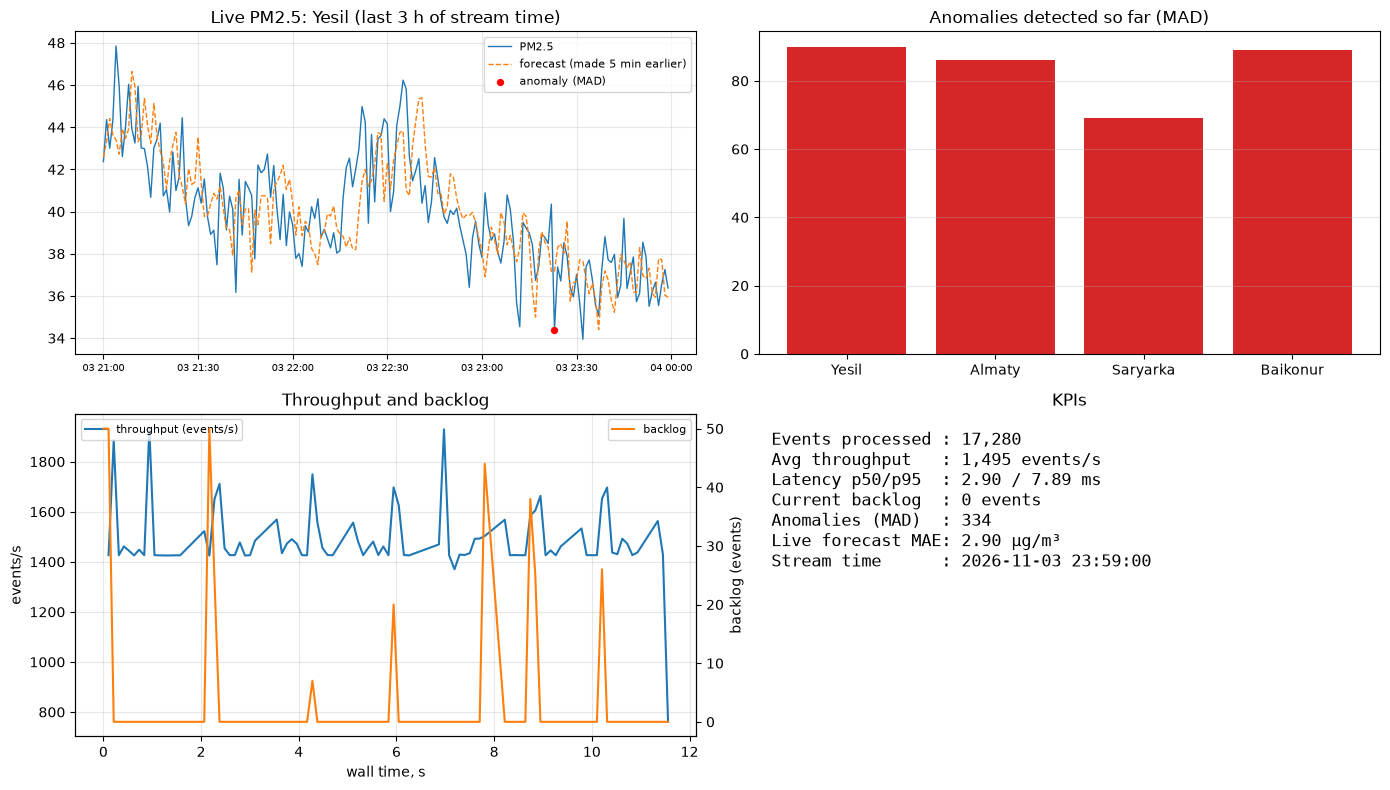

In [5]:
def draw_dashboard(res, mon, cfg, focus='Yesil'):
    df = pd.DataFrame(res)
    m = pd.DataFrame(mon)
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    # (1) live PM2.5 + forecast + anomalies
    ax = axes[0, 0]
    g = df[df.sensor_id == focus].sort_values('timestamp')
    if len(g):
        g = g[g.timestamp > g.timestamp.max() - pd.Timedelta('3h')]
        ax.plot(g.timestamp, g.pm25, lw=1, label='PM2.5')
        ax.plot(g.timestamp, g.pred_for_now, lw=1, ls='--', label=f"forecast (made {cfg['horizon_min']} min earlier)")
        a = g[g.mad_flag]
        ax.scatter(a.timestamp, a.pm25, c='red', s=18, zorder=3, label='anomaly (MAD)')
    ax.set_title(f'Live PM2.5: {focus} (last 3 h of stream time)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.tick_params(axis='x', labelsize=7)

    # (2) anomaly counts per sensor
    ax = axes[0, 1]
    cnt = df.groupby('sensor_id')['mad_flag'].sum().reindex(cfg['sensors'], fill_value=0)
    ax.bar(cnt.index, cnt.values, color='tab:red')
    ax.set_title('Anomalies detected so far (MAD)'); ax.grid(alpha=0.3, axis='y')

    # (3) throughput and backlog
    ax = axes[1, 0]
    if len(m) > 1:
        thr = m.processed.diff() / m.t.diff()
        ax.plot(m.t, thr, label='throughput (events/s)')
        ax.set_xlabel('wall time, s'); ax.set_ylabel('events/s')
        ax2 = ax.twinx(); ax2.plot(m.t, m.backlog, color='tab:orange', label='backlog'); ax2.set_ylabel('backlog (events)')
        ax.legend(loc='upper left', fontsize=8); ax2.legend(loc='upper right', fontsize=8)
    ax.set_title('Throughput and backlog'); ax.grid(alpha=0.3)

    # (4) KPI panel
    ax = axes[1, 1]; ax.axis('off')
    lat = (df.t_done - df.t_ingest) * 1000
    ok = df.dropna(subset=['pred_for_now'])
    mae = (ok.pm25 - ok.pred_for_now).abs().mean() if len(ok) else np.nan
    elapsed = m.t.iloc[-1] if len(m) else np.nan
    txt = (f"Events processed : {len(df):,}\n"
           f"Avg throughput   : {len(df) / elapsed:,.0f} events/s\n"
           f"Latency p50/p95  : {lat.median():.2f} / {lat.quantile(0.95):.2f} ms\n"
           f"Current backlog  : {int(m.backlog.iloc[-1]) if len(m) else 0} events\n"
           f"Anomalies (MAD)  : {int(df.mad_flag.sum())}\n"
           f"Live forecast MAE: {mae:.2f} µg/m³\n"
           f"Stream time      : {df.timestamp.max()}")
    ax.text(0.02, 0.95, txt, va='top', family='monospace', fontsize=12)
    ax.set_title('KPIs')
    fig.tight_layout()
    return fig

def run_pipeline(events, cfg, live=False):
    n = cfg['n_partitions']
    part_qs = [queue.Queue() for _ in range(n)]
    out_q = queue.Queue()
    workers = [threading.Thread(target=worker, args=(i, part_qs[i], out_q, cfg), daemon=True) for i in range(n)]
    prod = threading.Thread(target=producer, args=(events, part_qs, cfg), daemon=True)
    results, monitor = [], []
    t_start = time.perf_counter()
    for w in workers: w.start()
    prod.start()

    last_draw = 0.0
    while True:
        alive = prod.is_alive() or any(w.is_alive() for w in workers)
        while True:
            try:
                results.append(out_q.get_nowait())
            except queue.Empty:
                break
        now = time.perf_counter() - t_start
        monitor.append({'t': now, 'processed': len(results),
                        'backlog': sum(q.qsize() for q in part_qs)})
        if live and results and now - last_draw >= cfg['dashboard_refresh_s']:
            fig = draw_dashboard(results, monitor, cfg)
            clear_output(wait=True); display(fig); plt.close(fig)
            last_draw = now
        if not alive and out_q.empty():
            break
        time.sleep(0.1)
    wall = time.perf_counter() - t_start
    if live:
        fig = draw_dashboard(results, monitor, cfg)
        clear_output(wait=True); display(fig); plt.close(fig)
    res = pd.DataFrame(results).sort_values(['sensor_id', 'timestamp']).reset_index(drop=True)
    return res, pd.DataFrame(monitor), wall

events = data.drop(columns=['is_anomaly', 'anomaly_type']).to_dict('records')   # detectors never see labels
res, mon, wall = run_pipeline(events, CONFIG, live=True)

In [6]:
print(f'{len(res):,} events processed in {wall:.1f} s by {CONFIG["n_partitions"]} workers')
# bring back the ground-truth labels (evaluation only)
res = res.merge(data[['timestamp', 'sensor_id', 'is_anomaly', 'anomaly_type']], on=['timestamp', 'sensor_id'])
res['latency_ms'] = (res.t_done - res.t_ingest) * 1000
res.head()

17,280 events processed in 11.6 s by 2 workers


,timestamp,sensor_id,pm25,temp_c,wind_mps,partition,t_ingest,worker,mad_score,mad_flag,z_score,z_flag,forecast_tplusH,pred_for_now,naive_for_now,t_done,is_anomaly,anomaly_type,latency_ms
0,2026-11-01 00:00:00,Almaty,29.07,-10.56,4.24,1,366595.309284,1,NaN,False,NaN,False,NaN,NaN,NaN,366595.309370,0,normal,0.086500
1,2026-11-01 00:01:00,Almaty,27.81,-10.44,5.14,1,366595.309294,1,NaN,False,NaN,False,NaN,NaN,NaN,366595.309379,0,normal,0.085083
2,2026-11-01 00:02:00,Almaty,30.31,-11.07,4.54,1,366595.309297,1,NaN,False,NaN,False,NaN,NaN,NaN,366595.309382,0,normal,0.084625
3,2026-11-01 00:03:00,Almaty,29.60,-10.85,5.31,1,366595.309301,1,NaN,False,NaN,False,NaN,NaN,NaN,366595.309385,0,normal,0.083917
4,2026-11-01 00:04:00,Almaty,29.59,-11.11,5.14,1,366595.309305,1,NaN,False,NaN,False,NaN,NaN,NaN,366595.309387,0,normal,0.082500


## 5. Operational characteristics
Measured from the run above: **throughput**, **end-to-end latency**, **backlog** and **event count per worker/partition**.

In [7]:
lat = res.latency_ms
ops = pd.Series({
    'events processed': len(res),
    'wall time, s': round(wall, 2),
    'throughput, events/s': round(len(res) / wall, 1),
    'latency p50, ms': round(lat.median(), 3),
    'latency p95, ms': round(lat.quantile(0.95), 3),
    'latency p99, ms': round(lat.quantile(0.99), 3),
    'latency max, ms': round(lat.max(), 3),
    'backlog mean, events': round(mon.backlog.mean(), 1),
    'backlog max, events': int(mon.backlog.max()),
})
display(ops.to_frame('value'))
display(res.groupby(['partition', 'worker']).agg(events=('pm25', 'size'),
                                                 sensors=('sensor_id', lambda s: ', '.join(sorted(s.unique())))))

,value
events processed,17280.000
"wall time, s",11.560
"throughput, events/s",1494.800
"latency p50, ms",2.902
"latency p95, ms",7.887
"latency p99, ms",24.826
"latency max, ms",58.378
"backlog mean, events",3.800
"backlog max, events",50.000


,,events,sensors
partition,worker,,
0,0,8640,"Baikonur, Yesil"
1,1,8640,"Almaty, Saryarka"


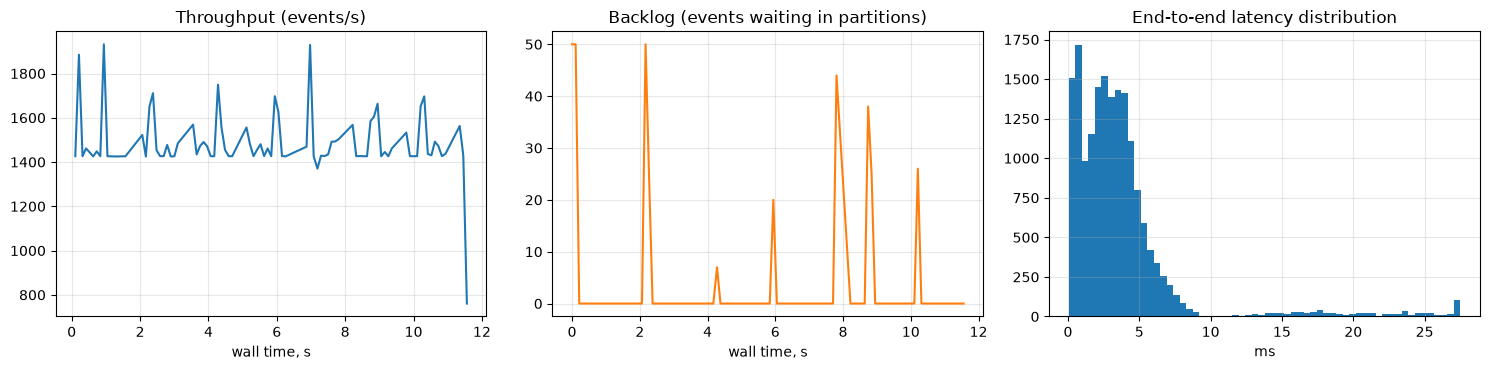

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(mon.t, mon.processed.diff() / mon.t.diff())
axes[0].set_title('Throughput (events/s)'); axes[0].set_xlabel('wall time, s')
axes[1].plot(mon.t, mon.backlog, color='tab:orange')
axes[1].set_title('Backlog (events waiting in partitions)'); axes[1].set_xlabel('wall time, s')
axes[2].hist(lat.clip(upper=lat.quantile(0.995)), bins=60)
axes[2].set_title('End-to-end latency distribution'); axes[2].set_xlabel('ms')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 5.1 Scaling experiment: 1 vs 2 vs 4 workers (no rate limit, no dashboard)
The producer replays as fast as it can. This shows the maximum throughput and how backlog and latency grow when the consumers cannot keep up.

In [9]:
rows = []
for n in [1, 2, 4]:
    cfg_b = {**CONFIG, 'n_partitions': n, 'replay_rate_eps': 0}
    r, m, w = run_pipeline(events, cfg_b, live=False)
    l = (r.t_done - r.t_ingest) * 1000
    rows.append({'workers': n,
                 'events per partition': r.groupby('partition').size().reindex(range(n), fill_value=0).tolist(),
                 'throughput ev/s': round(len(r) / w), 'latency p50 ms': round(l.median(), 1),
                 'latency p95 ms': round(l.quantile(0.95), 1), 'max backlog': int(m.backlog.max())})
scaling = pd.DataFrame(rows)
scaling

,workers,events per partition,throughput ev/s,latency p50 ms,latency p95 ms,max backlog
0,1,[17280],18358,431.2,805.9,14288
1,2,"[8640, 8640]",13629,563.6,1131.8,17174
2,4,"[0, 4320, 8640, 4320]",15901,549.5,994.7,17150


**Interpretation**
* Without a rate limit the producer pushes all 17,280 events into the queues almost immediately, so the **backlog** climbs to ~15k and latency becomes queueing time (hundreds of ms). With the 1,500 ev/s replay rate in §4 the workers keep up: the backlog stays near 0 and p50 latency is a few ms. This is the typical streaming trade-off: when the input rate exceeds the processing rate, backlog and latency grow.
* More threads did **not** raise throughput (it even dropped slightly). The work is CPU-bound Python, so the GIL lets only one thread run at a time, and extra threads only add switching overhead. Real scale-out needs separate processes or machines (Kafka consumer group, Spark/Flink executors). The partitioning logic would stay exactly the same.
* With 4 partitions and only 4 keys the hash puts two sensors in one partition and leaves another empty (`[0, 4320, 8640, 4320]`). This is **partition skew**: key-based partitioning only balances well when there are many more keys than partitions.

## 6. Time-series analysis
Uses the processed stream: **resampling** (1-min → 15-min and hourly), **rolling windows** (1 h and 24 h), and a **trend + daily seasonality decomposition**:
* trend = centred 24-hour rolling mean of the hourly median (one full daily cycle, so the seasonality averages out)
* seasonal = average of the detrended series for each hour of the day
* residual = series − trend − seasonal

The hourly **median** is used so the injected anomalies do not distort the analysis.

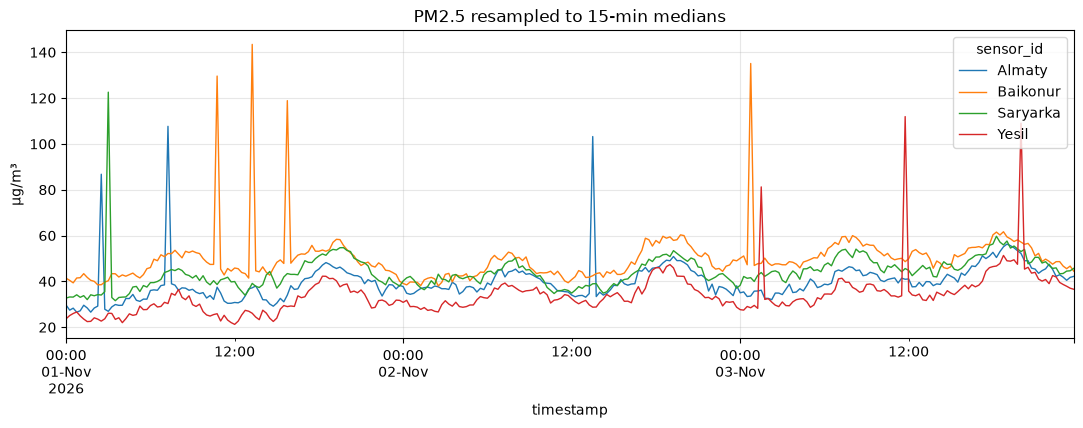

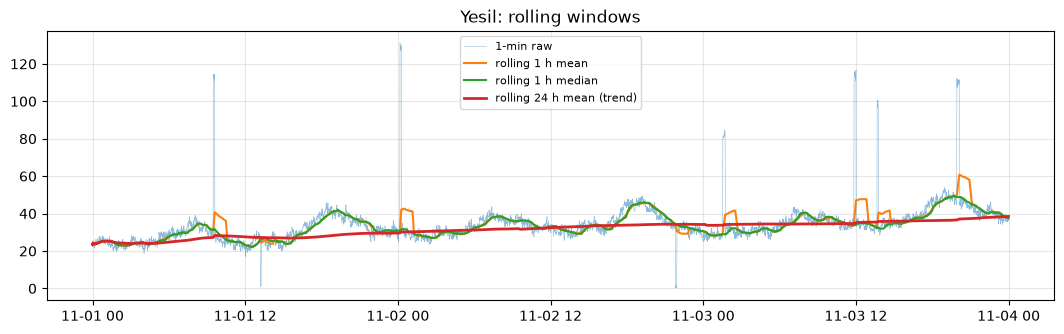

In [10]:
ts = res.set_index('timestamp')
r15 = ts.groupby('sensor_id')['pm25'].resample('15min').median().unstack(0)
fig, ax = plt.subplots(figsize=(13, 4))
r15.plot(ax=ax, lw=1)
ax.set_title('PM2.5 resampled to 15-min medians'); ax.set_ylabel('µg/m³'); ax.grid(alpha=0.3)
plt.show()

s = ts[ts.sensor_id == 'Yesil']['pm25']
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(s.index, s, lw=0.4, alpha=0.5, label='1-min raw')
ax.plot(s.rolling('1h').mean(), label='rolling 1 h mean')
ax.plot(s.rolling('1h').median(), label='rolling 1 h median')
ax.plot(s.rolling('24h').mean(), lw=2, label='rolling 24 h mean (trend)')
ax.set_title('Yesil: rolling windows'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

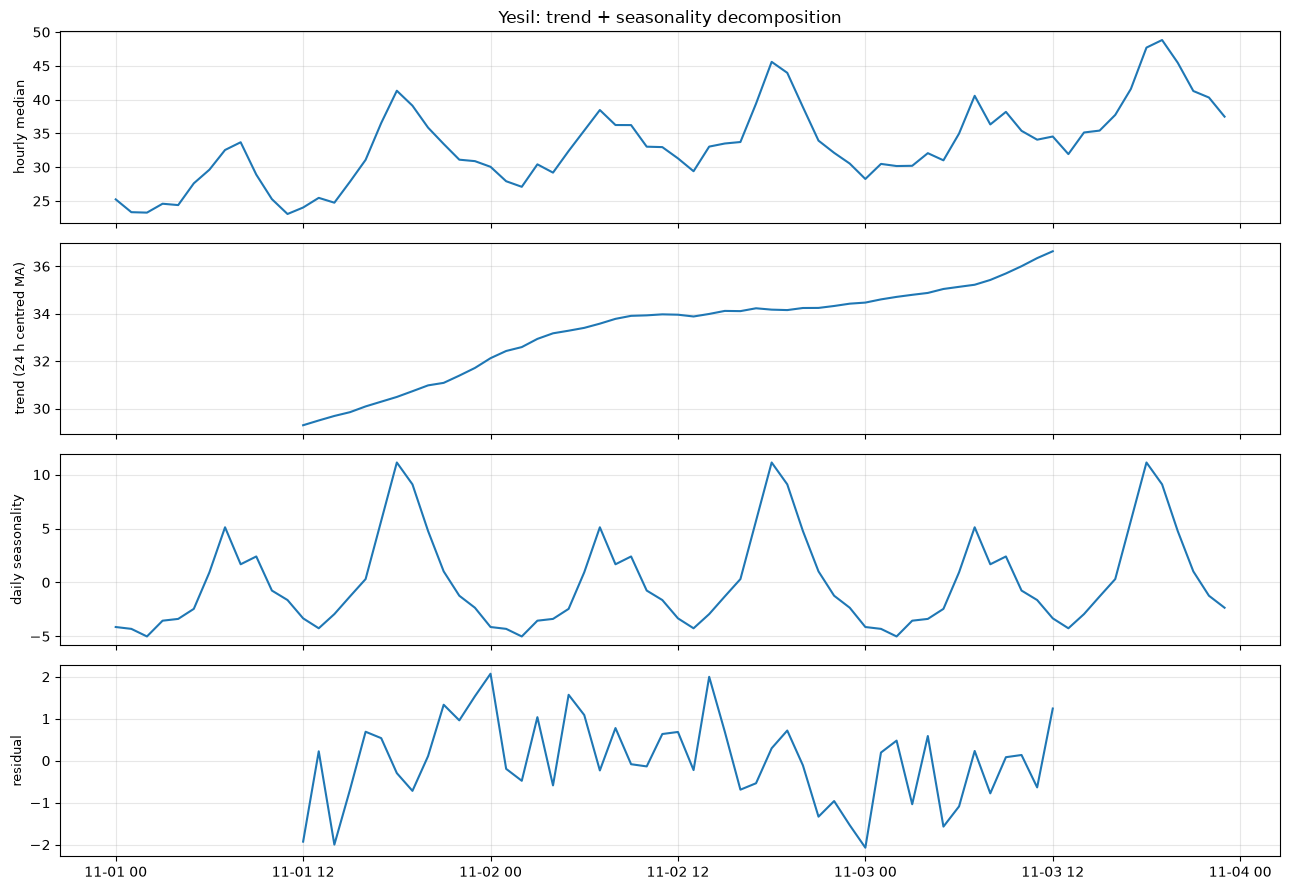

Trend slope: 3.67 µg/m³ per day (generator: +3.0)
Seasonal peaks: 18:00 (max 11.1), morning max at 7:00; minimum at 2:00
Residual std: 1.01  vs hourly series std: 5.97


In [11]:
hourly = s.resample('1h').median()
trend = hourly.rolling(24, center=True).mean()
detr = hourly - trend
seasonal_profile = detr.groupby(detr.index.hour).mean()
seasonal = pd.Series(seasonal_profile.reindex(hourly.index.hour).values, index=hourly.index)
resid = hourly - trend - seasonal

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for a, (name, y) in zip(axes, [('hourly median', hourly), ('trend (24 h centred MA)', trend),
                               ('daily seasonality', seasonal), ('residual', resid)]):
    a.plot(y.index, y); a.set_ylabel(name, fontsize=9); a.grid(alpha=0.3)
axes[0].set_title('Yesil: trend + seasonality decomposition')
plt.tight_layout(); plt.show()

days = (trend.dropna().index[-1] - trend.dropna().index[0]) / pd.Timedelta('1D')
print(f'Trend slope: {(trend.dropna().iloc[-1] - trend.dropna().iloc[0]) / days:.2f} µg/m³ per day (generator: +3.0)')
print(f'Seasonal peaks: {seasonal_profile.idxmax()}:00 (max {seasonal_profile.max():.1f}), '
      f'morning max at {seasonal_profile.loc[5:11].idxmax()}:00; minimum at {seasonal_profile.idxmin()}:00')
print(f'Residual std: {resid.std():.2f}  vs hourly series std: {hourly.std():.2f}')

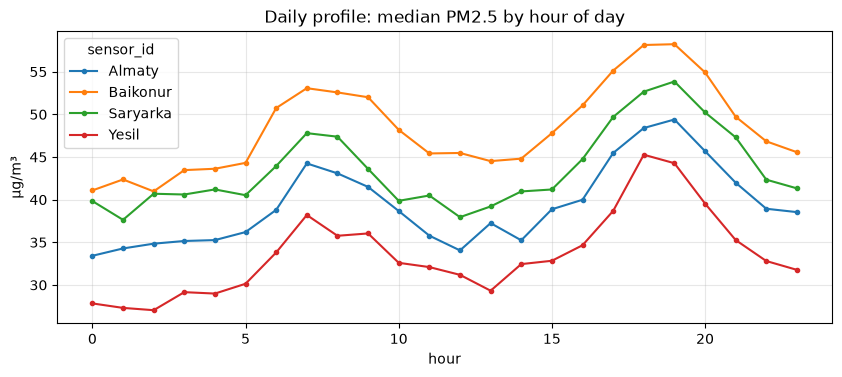

In [12]:
prof = ts.assign(hour=ts.index.hour).groupby(['hour', 'sensor_id'])['pm25'].median().unstack()
ax = prof.plot(figsize=(10, 3.8), marker='o', ms=3)
ax.set_title('Daily profile: median PM2.5 by hour of day'); ax.set_xlabel('hour'); ax.set_ylabel('µg/m³'); ax.grid(alpha=0.3)
plt.show()

**Findings**
* **Daily seasonality** is clearly visible in all districts: a morning peak around 07–08 h and a larger evening peak around 18–19 h, with the minimum at night (≈02 h). This matches the traffic and heating pattern built into the generator. 3 days of 1-minute data are enough to see it, whereas Assignment 3's 70 minutes were not.
* **Trend**: the 24 h rolling mean rises by ≈3.7 µg/m³ per day (true value +3.0). The difference comes from the wind cycle (period 1.7 days), which the 24 h window cannot fully average out.
* After removing trend and seasonality the **residual std falls from ≈6.0 to ≈1.0**, so these two components explain most of the hourly variation.
* District levels differ (Yesil lowest, Baikonur highest), but the shape of the daily profile is the same for all of them, so one seasonal model could be shared.

## 7. Anomaly detection evaluation
The online flags from the stream are compared with the injected ground truth.
* **Point level:** precision, recall, F1 over all minutes
* **Event level:** an injected episode counts as detected if any of its minutes is flagged; **detection delay** = minutes from episode start to first flag

In [13]:
def point_metrics(y, p):
    return {'precision': precision_score(y, p), 'recall': recall_score(y, p), 'F1': f1_score(y, p),
            'flags': int(p.sum()), 'false positives': int(((p == 1) & (y == 0)).sum())}

y = res.is_anomaly
pm_tab = pd.DataFrame({'Rolling MAD (k=4)': point_metrics(y, res.mad_flag.astype(int)),
                       'Rolling z-score (k=3)': point_metrics(y, res.z_flag.astype(int))}).T
display(pm_tab.round(3))

for name, col in [('Rolling MAD', 'mad_flag'), ('Rolling z-score', 'z_flag')]:
    print(name, 'confusion matrix [[TN FP] [FN TP]]:\n', confusion_matrix(y, res[col]))

,precision,recall,F1,flags,false positives
Rolling MAD (k=4),0.787,1.000,0.881,334.0,71.0
Rolling z-score (k=3),0.347,0.365,0.356,277.0,181.0


Rolling MAD confusion matrix [[TN FP] [FN TP]]:
 [[16946    71]
 [    0   263]]
Rolling z-score confusion matrix [[TN FP] [FN TP]]:
 [[16836   181]
 [  167    96]]


In [14]:
# episodes = runs of consecutive labelled minutes per sensor
res['episode'] = res.groupby('sensor_id')['is_anomaly'].transform(lambda s: (s.diff() != 0).cumsum())
eps = res[res.is_anomaly == 1]

def episode_eval(col):
    rows = []
    for (sid, e), g in eps.groupby(['sensor_id', 'episode']):
        hit = g[g[col]]
        rows.append({'type': g.anomaly_type.iloc[0], 'detected': len(hit) > 0,
                     'delay_min': (hit.timestamp.min() - g.timestamp.min()) / pd.Timedelta('1min') if len(hit) else np.nan,
                     'minute_recall': g[col].mean()})
    return pd.DataFrame(rows)

ev_rows = []
for name, col in [('Rolling MAD', 'mad_flag'), ('Rolling z-score', 'z_flag')]:
    e = episode_eval(col)
    for t, g in e.groupby('type'):
        ev_rows.append({'method': name, 'type': t, 'episodes': len(g), 'detected': int(g.detected.sum()),
                        'mean delay, min': g.delay_min.mean(), 'share of minutes flagged': g.minute_recall.mean()})
pd.DataFrame(ev_rows).round(2)

,method,type,episodes,detected,"mean delay, min",share of minutes flagged
0,Rolling MAD,dropout,8,8,0.0,1.00
1,Rolling MAD,spike,24,24,0.0,1.00
2,Rolling z-score,dropout,8,8,0.0,0.68
3,Rolling z-score,spike,24,23,0.0,0.36


,k,MAD F1,MAD precision,MAD recall,z F1,z recall
0,2.5,0.373,0.229,1.000,0.295,0.532
1,3.0,0.577,0.405,1.000,0.356,0.365
2,3.5,0.760,0.613,1.000,0.443,0.350
3,4.0,0.881,0.787,1.000,0.366,0.236
4,5.0,0.972,0.946,1.000,0.369,0.228
5,6.0,0.989,0.978,1.000,0.211,0.118
6,8.0,0.998,1.000,0.996,0.211,0.118


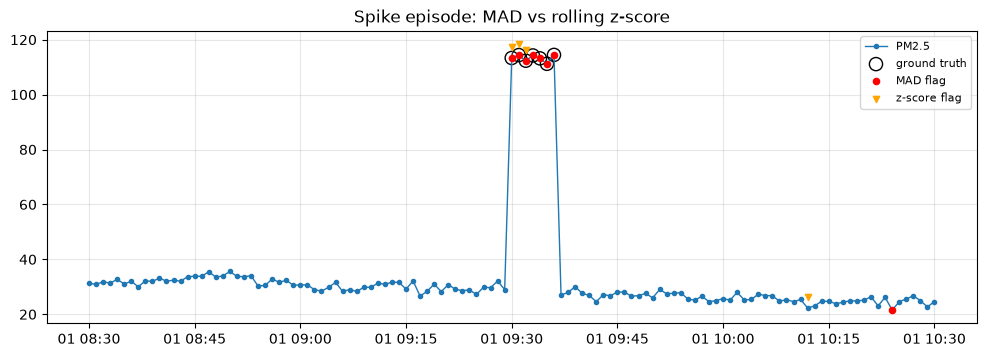

In [15]:
# Threshold sensitivity, computed offline from the scores saved by the stream
rows = []
for k in [2.5, 3, 3.5, 4, 5, 6, 8]:
    rows.append({'k': k, 'MAD F1': f1_score(y, res.mad_score > k), 'MAD precision': precision_score(y, res.mad_score > k),
                 'MAD recall': recall_score(y, res.mad_score > k),
                 'z F1': f1_score(y, res.z_score > k), 'z recall': recall_score(y, res.z_score > k)})
sens = pd.DataFrame(rows).round(3)
display(sens)

# visual example: the first spike episode of Yesil
g = res[res.sensor_id == 'Yesil'].set_index('timestamp')
t0 = g[g.anomaly_type == 'spike'].index.min()
w = g.loc[t0 - pd.Timedelta('60min'): t0 + pd.Timedelta('60min')]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(w.index, w.pm25, marker='.', lw=1, label='PM2.5')
ax.scatter(w.index[w.is_anomaly == 1], w.pm25[w.is_anomaly == 1], s=90, facecolors='none', edgecolors='k', label='ground truth')
ax.scatter(w.index[w.mad_flag], w.pm25[w.mad_flag], c='red', s=20, label='MAD flag', zorder=3)
ax.scatter(w.index[w.z_flag], w.pm25[w.z_flag] + 4, c='orange', marker='v', s=20, label='z-score flag', zorder=3)
ax.set_title('Spike episode: MAD vs rolling z-score'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

**Findings**
* **Rolling MAD is clearly better**: recall 1.00 (every anomalous minute caught), precision 0.79, F1 0.88. All 32 injected episodes are detected with **0 minutes delay**.
* **Rolling z-score** detects the *first* minute of nearly every spike, then misses the rest (only 36% of spike minutes flagged, F1 0.36). Once a spike enters the window, it inflates the mean and std (**masking**). This is the same effect seen in Assignment 3. The median and MAD are not affected while less than half of the window is anomalous.
* The 71 MAD false positives are normal fluctuations at k = 4. The sensitivity table shows F1 rising to 0.97 at k = 5 and 0.99 at k = 6 with recall unchanged. k = 4 was fixed before evaluation. Choosing k from this table would be tuning on the test labels, so in practice k should be set on a separate validation period (here the data suggest k ≈ 5–6).

## 8. Machine-learning evaluation (online 5-minute-ahead forecast)
Prequential evaluation: each prediction was made **before** its true value was known, and the model only learned from it afterwards. The first 6 h are excluded (warm-up). Baseline: **persistence** (PM2.5 in 5 minutes = PM2.5 now).

Two subsets are reported:
* **all points**
* **normal points**: neither the time of the forecast nor the target minute is an injected anomaly. Spikes cannot be predicted from the past, so they mainly measure the size of the anomaly.

In [16]:
H = CONFIG['horizon_min']
res['label_at_origin'] = res.groupby('sensor_id')['is_anomaly'].shift(H)
start = res.timestamp.min() + pd.Timedelta(minutes=CONFIG['warmup_min'])
ev = res[(res.timestamp >= start) & res.pred_for_now.notna()].copy()
normal = ev[(ev.is_anomaly == 0) & (ev.label_at_origin == 0)]

def reg_metrics(d):
    out = {}
    for name, col in [('Online SGD model', 'pred_for_now'), ('Persistence baseline', 'naive_for_now')]:
        out[name] = {'MAE': mean_absolute_error(d.pm25, d[col]),
                     'RMSE': np.sqrt(mean_squared_error(d.pm25, d[col]))}
    return pd.DataFrame(out).T

ml_tab = pd.concat({'all points': reg_metrics(ev), 'normal points': reg_metrics(normal)}, axis=0).round(3)
display(ml_tab)
imp = 1 - ml_tab.loc[('normal points', 'Online SGD model'), 'MAE'] / ml_tab.loc[('normal points', 'Persistence baseline'), 'MAE']
print(f'MAE improvement over persistence on normal points: {imp:.1%}  (n = {len(normal):,} forecasts)')

MAE    RMSE
all points    Online SGD model      2.902   9.619
              Persistence baseline  3.011  10.146
normal points Online SGD model      1.670   2.182
              Persistence baseline  1.763   2.206

MAE improvement over persistence on normal points: 5.3%  (n = 15,459 forecasts)


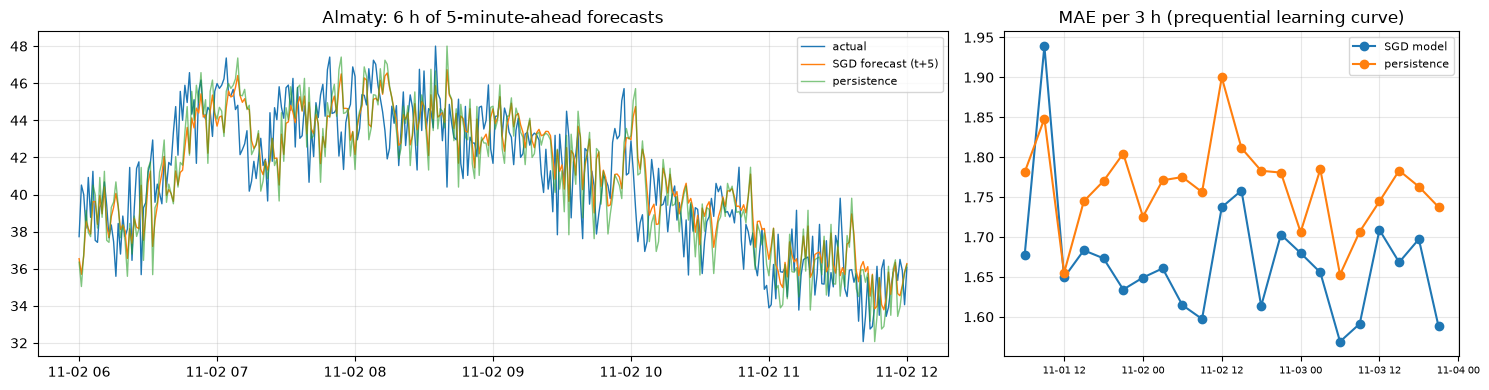

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [2, 1]})
g = normal[normal.sensor_id == 'Almaty'].set_index('timestamp')
g = g.loc[g.index[0] + pd.Timedelta('1D'): g.index[0] + pd.Timedelta('1D 6h')]
axes[0].plot(g.index, g.pm25, lw=1, label='actual')
axes[0].plot(g.index, g.pred_for_now, lw=1, label='SGD forecast (t+5)')
axes[0].plot(g.index, g.naive_for_now, lw=1, alpha=0.6, label='persistence')
axes[0].set_title('Almaty: 6 h of 5-minute-ahead forecasts'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

err = normal.set_index('timestamp').sort_index()
ae_m = (err.pm25 - err.pred_for_now).abs().resample('3h').mean()
ae_n = (err.pm25 - err.naive_for_now).abs().resample('3h').mean()
axes[1].plot(ae_m.index, ae_m, marker='o', label='SGD model'); axes[1].plot(ae_n.index, ae_n, marker='o', label='persistence')
axes[1].set_title('MAE per 3 h (prequential learning curve)'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
axes[1].tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.show()

**Findings**
* On normal points the online model beats persistence (MAE 1.67 vs 1.76, about 5% better; RMSE 2.18 vs 2.21) over ~15k truly out-of-sample forecasts. The gain is modest because a large part of the 1-minute signal is unpredictable sensor noise. The model mainly learns to **partially revert noisy jumps toward the recent mean** instead of copying them.
* On *all* points both errors grow a lot (RMSE ≈ 10): spikes and dropouts are sudden and cannot be forecast from the past, which is exactly why the anomaly detector is needed alongside the forecaster.
* The learning curve shows the model better than persistence in almost every 3 h block after the first few hours. It keeps learning online without retraining from scratch.
* **No leakage**: features use only values ≤ t, labels are revealed only H minutes later, and evaluation is test-then-train, so every error is measured on data the model had not seen.

## 9. Conclusions and limitations
* The system ingests a keyed, partitioned stream with a producer and parallel consumer workers. Each worker keeps per-sensor state and runs detection and ML per event in a few ms at 1,500 events/s.
* The **live dashboard** shows the stream, forecasts, anomaly counts, throughput, backlog and latency while the data arrives.
* **Time-series analysis** recovers the built-in daily seasonality (07–08 h and 18–19 h peaks) and the upward trend.
* The **rolling MAD detector** finds 100% of anomalies with no delay (F1 0.88, ≈0.97 with k = 5), while the rolling z-score suffers from masking (F1 0.36).
* The **online SGD forecaster** improves on persistence by ~5% MAE using only information available at prediction time.
* **Operational measurements** show a backlog and latency explosion when input rate > processing rate, and that threads do not scale CPU work because of the GIL.

**Limitations**
* The data is synthetic, so real sensors would add missing values, irregular timestamps and calibration drift.
* Workers are **threads**. Python's GIL means they do not run CPU work in parallel. The architecture (key-partitioned stream, one consumer per partition, local state) maps directly onto Kafka topic partitions + a consumer group, or onto Spark/Flink keyed streams, where workers are separate processes or machines.
* Dashboard redraws run in the sink thread and briefly hold the GIL, which shows up as occasional latency outliers.
* The anomaly baseline (30 min) reacts slowly to genuine fast level shifts. Such a shift is flagged for a few minutes until the window catches up.

## 10. Reproducibility
```bash
cd projects-for-uni
source venv/bin/activate                     # Python 3.14, see requirements.txt
cd realtime_endterm
jupyter nbconvert --to notebook --execute --inplace main.ipynb   # or open main.ipynb and Run All
```
* `CONFIG` (also written to `config.json`) controls everything. `seed=42` gives an identical dataset on every run.
* The generated stream is saved to `data/astana_pm25_stream.csv`.
* Timing numbers (throughput, latency) depend on the machine. Detection and ML metrics are deterministic for the same data, apart from tiny differences from thread scheduling (the per-worker model mixes its sensors' events in arrival order).